# Executive Summary

This analysis compares GPA and continuation outcomes for students grouped by their most recently recorded English test, or by having no test recorded.

- **GPA:** Among 5,485 records, average GPA was highest for TOEFL students (3.79), followed by Duolingo (3.75), students with no test recorded (3.71), and IELTS students (3.66). These results describe differences between groups; they do not show that a test caused a GPA outcome.
- **Continuation:** In the same 5,485 records, 136 were marked as discontinued (2.48%). The rates were 3.56% for students with no test recorded, 2.26% for TOEFL, 1.56% for IELTS, and 1.14% for Duolingo. The comparison identified a difference between IELTS and the no-test group; it did not identify clear differences for the other group pairs.
- **What leaders should take away:** TOEFL students had the highest average GPA, and the no-test group had the highest recorded discontinuation rate. These patterns are useful signals for follow-up, not evidence that requiring or choosing a particular test will improve student outcomes.

The GPA analysis excluded test groups with very few records and unusually high or low GPA values. The Duolingo group is also much smaller than the IELTS and no-test groups. Students may have more than one admission record, and other factors may contribute to the observed differences.

# English Language Proficiency Tests Analysis

In [32]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)
    
import warnings

warnings.filterwarnings('ignore')

from scripts.functions import (
    anova_test,
    bar_plot,
    box_plot,
    boxcox_tranformation,
    check_homoscedasticity,
    check_normality,
    data_pull,
    fisher_exact_test,
    get_density_plot,
    get_qq_plot,
    kruskal_wallis_test,
    mann_whitney_test,
    remove_outliers,
    summarize,
    t_test_bonferroni,
)


## Data Preparations and Preprocessing Steps

**1. Identification and Mapping of English Tests**

>The initial step involves identifying distinct records for each student, denoted by their unique student ID (Emplid). These records encompass the dates of English proficiency tests (TestDate) undertaken by students. To ensure consistency and clarity, the specific English test components are mapped to standardized English test names (EnglishTestName). This mapping is accomplished through conditional statements based on the Test_Component column values, enabling a coherent categorization of English proficiency tests.

**2. Selection of Relevant English Test Data**

>Subsequently, the data set is refined to include only records pertinent to English proficiency tests. This refinement involves filtering out records where the English test name is not explicitly specified, ensuring the inclusion of only comprehensive and informative data points for analysis.

**3. Determination of Latest English Test Record**

>To facilitate accurate analysis of students' most recent English proficiency achievements, a mechanism is established to identify the latest English test record for each student. This is achieved through the assignment of row numbers within each student group, ordered by test date in descending order. Consequently, the most recent English proficiency test record for each student is selected based on the assigned row number.

**4. Identification of Withdrawal Instances**

>An integral aspect of the data preparation process involves identifying instances where students have withdrawn from their academic programs. Specifically, distinct admission application numbers associated with graduate students who withdrew or cancelled their admissions after the 2201 term are extracted. This filtering mechanism ensures the isolation of relevant withdrawal data, critical for subsequent analysis and decision-making processes.

**5. Compilation of Enrollment Data:**

>Enrollment data, comprising essential attributes such as student ID (Emplid), cumulative GPA, academic program, and discontinuation status, is systematically compiled. Row numbers are assigned within each admission application number group, ordered by term in descending order, to facilitate the selection of the latest enrollment data for each student.

**6. Integration of English Test and Enrollment Data**

>The final step involves integrating the compiled enrollment data with the latest English proficiency test data for each student. Through a comprehensive join operation, students' English test names are mapped based on their respective student IDs (Emplid). In cases where students have not undertaken an English proficiency test, the English test name is designated as 'No Test,' ensuring uniformity and completeness of the dataset.

**7. Data Aggregations**

>Following the data preparation and preprocessing steps, required data was pulled from SQL Server and descriptive values (such as counts, averages, total) were calculated in Python using pandas dataframes. 

## Descriptives for ELP Tests

In [33]:
ELP_df = data_pull(query_sql_file='sql_queries/AllTests.sql')

Counts of ELP Tests

In [34]:
ELP_df[['EnglishTestName', 'Emplid']].drop_duplicates()['EnglishTestName'].value_counts(sort=True)

EnglishTestName
International English Language Testing System (IELTS)             23791
Test of English as a Foreign Language (TOEFL)                      5200
Duolingo                                                           4414
Pearson Test of English (PTE)                                       572
The Canadian Academic English Language (CAEL)                        52
Cambridge English Assessment - Advanced (CAE)                        50
English for Academic Purposes (EAP)                                  33
Cambridge English Assessment - Proficiency (CPE)                      6
Advanced Placement (AP) International English Language (APIEL)        2
Test of Written English (TWE)                                         1
Test of Spoken English (TSE)                                          1
Michigan English Language Assessment Battery (MELAB)                  1
Name: count, dtype: int64

Counts of ELP tests only for the latest tests for each student.

In [35]:
ELP_df.sort_values(by='TestDate', ascending=False).drop_duplicates(subset='Emplid', keep='first')['EnglishTestName'].value_counts(sort=True)

EnglishTestName
International English Language Testing System (IELTS)             23650
Test of English as a Foreign Language (TOEFL)                      5095
Duolingo                                                           4292
Pearson Test of English (PTE)                                       565
The Canadian Academic English Language (CAEL)                        49
Cambridge English Assessment - Advanced (CAE)                        47
English for Academic Purposes (EAP)                                  33
Cambridge English Assessment - Proficiency (CPE)                      5
Michigan English Language Assessment Battery (MELAB)                  1
Test of Written English (TWE)                                         1
Advanced Placement (AP) International English Language (APIEL)        1
Name: count, dtype: int64

## Bivariate Analysis of ELP Tests and Student GPAs

In [36]:
df = data_pull(query_sql_file='sql_queries/Query.sql')
#TestName_dict = test_names()
#df['TestName'] = df['TestName'].map(TestName_dict)

The summary results are as:

In [37]:
summary_df = summarize(df, 'TestName')
summary_df.reset_index(inplace=True)

summary_df.rename(
    columns={
        "TestName": "Test",
        "Test_Count": "Count",
        "Average_GPA": "Avg. GPA",
        "Median_GPA": "Med. GPA", 
        "Discontinuation": "Disc.",
        "Discontinuation_Rate": "Disc. %",
    }, 
    inplace = True
)

summary_df.sort_values(by = 'Avg. GPA', ascending = False)

,Test,Count,Avg. GPA,Med. GPA,Disc.,Disc. %
5,EAP,4,3.807500,3.815,0,0.000000
2,TOEFL,406,3.770069,3.865,13,3.201970
1,No Test,2470,3.675237,3.750,126,5.101215
3,Duolingo,187,3.644241,3.825,9,4.812834
0,IELTS,2536,3.639461,3.675,70,2.760252
6,CAEL,2,3.620000,3.620,0,0.000000
4,PTE,74,3.498973,3.500,2,2.702703


In [38]:
mask = df['TestName'].isin(['TOEFL', 'No Test', 'Duolingo', 'IELTS'])
df = df[mask]

After removing the low count tests, the summary results are as:

In [39]:
summary_df = summarize(df, 'TestName')
summary_df.reset_index(inplace=True)

summary_df.rename(
    columns={
        "TestName": "Test",
        "Test_Count": "Count",
        "Average_GPA": "Avg. GPA",
        "Median_GPA": "Med. GPA", 
        "Discontinuation": "Disc.",
        "Discontinuation_Rate": "Disc. %",
    }, 
    inplace = True
)

summary_df.sort_values(by = 'Avg. GPA', ascending = False)

,Test,Count,Avg. GPA,Med. GPA,Disc.,Disc. %
2,TOEFL,406,3.770069,3.865,13,3.201970
1,No Test,2470,3.675237,3.750,126,5.101215
3,Duolingo,187,3.644241,3.825,9,4.812834
0,IELTS,2536,3.639461,3.675,70,2.760252


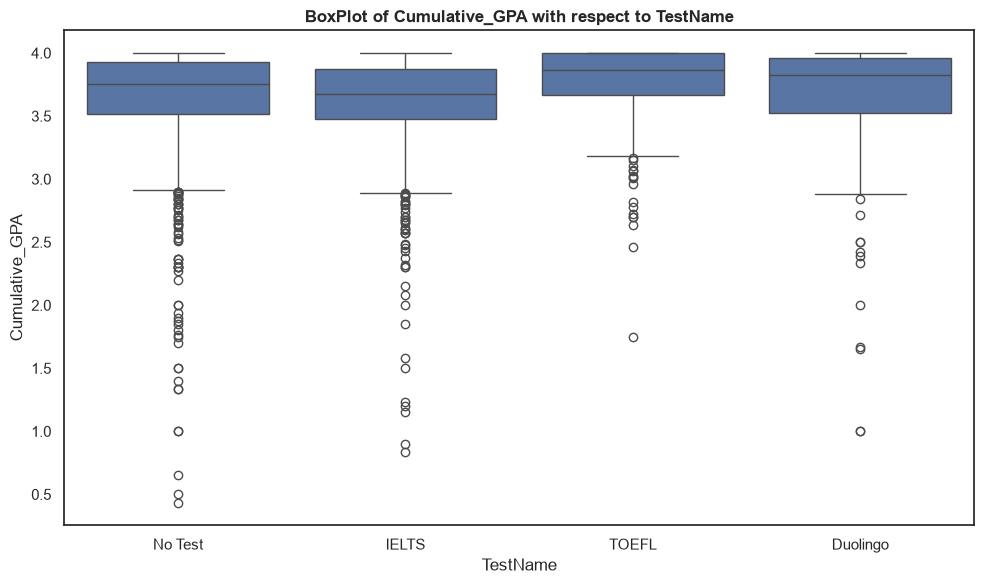

In [40]:
fig = box_plot(df=df,
               categoric_column='TestName',
               numeric_column='Cumulative_GPA')

fig.show()

In [41]:
df_cleaned = remove_outliers(df, column='Cumulative_GPA', k=1.5)

After removing the outliers, the summary results are as:

In [42]:
summary_df_cleaned = summarize(df_cleaned, 'TestName')
summary_df_cleaned.reset_index(inplace=True)

summary_df_cleaned.rename(
    columns={
        "TestName": "Test",
        "Test_Count": "Count",
        "Average_GPA": "Avg. GPA",
        "Median_GPA": "Med. GPA", 
        "Discontinuation": "Disc.",
        "Discontinuation_Rate": "Disc. %",
        "Continuation": "Cont."
    }, 
    inplace = True
)

summary_df_cleaned.sort_values(by = 'Avg. GPA', ascending = False)

,Test,Count,Avg. GPA,Med. GPA,Disc.,Disc. %
2,TOEFL,398,3.794183,3.8815,9,2.261307
3,Duolingo,175,3.751160,3.8500,2,1.142857
1,No Test,2415,3.709296,3.7670,86,3.561077
0,IELTS,2497,3.660416,3.6850,39,1.561874


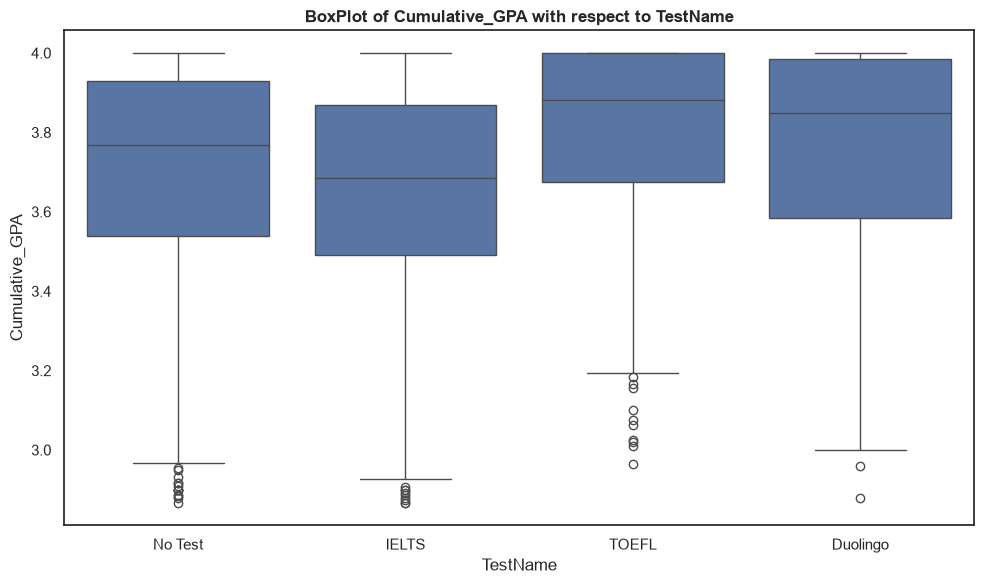

In [43]:
fig = box_plot(df=df_cleaned,
               categoric_column='TestName',
               numeric_column='Cumulative_GPA')

fig.show()

## Statistical Testing

ANOVA will be used to compare if the mean Cumulative GPA of test takers differ across the test types. ANOVA (Analysis of Variance) is a statistical test used to determine whether there are statistically significant differences between the means of three or more independent groups. However, before conducting an ANOVA test, it's important to check the assumptions of the test. If the assumptions (to be listed in the following part) are not met, then non-parametric tests must be implemented.

### Assumptions

The main assumptions of ANOVA are:

1. **Independence:** The observations within each group must be independent of each other.

2. **Normality:** The data within each group must be normally distributed.

3. **Homogeneity of Variance (Homoscedasticity):** The variance of the data must be approximately equal across all groups.

These assumptions are critical for the validity and interpretation of the ANOVA test results. Violations of these assumptions can lead to inaccurate conclusions.

#### **1. Independence**

The SQL query selects one latest-term enrollment record per admission application, but it does not ensure one record per student. A student with multiple applications may appear more than once, so row uniqueness alone does not establish independence. The tests below assume records are independent; this assumption should be verified at the student level or addressed with methods that account for repeated students.

#### **2. Normality**

This assumption is checked visually using Q-Q plots and histograms with density curves, and statistically using the Shapiro-Wilk test. These methods assess whether the GPA distribution within each group is consistent with normality, an ANOVA assumption.

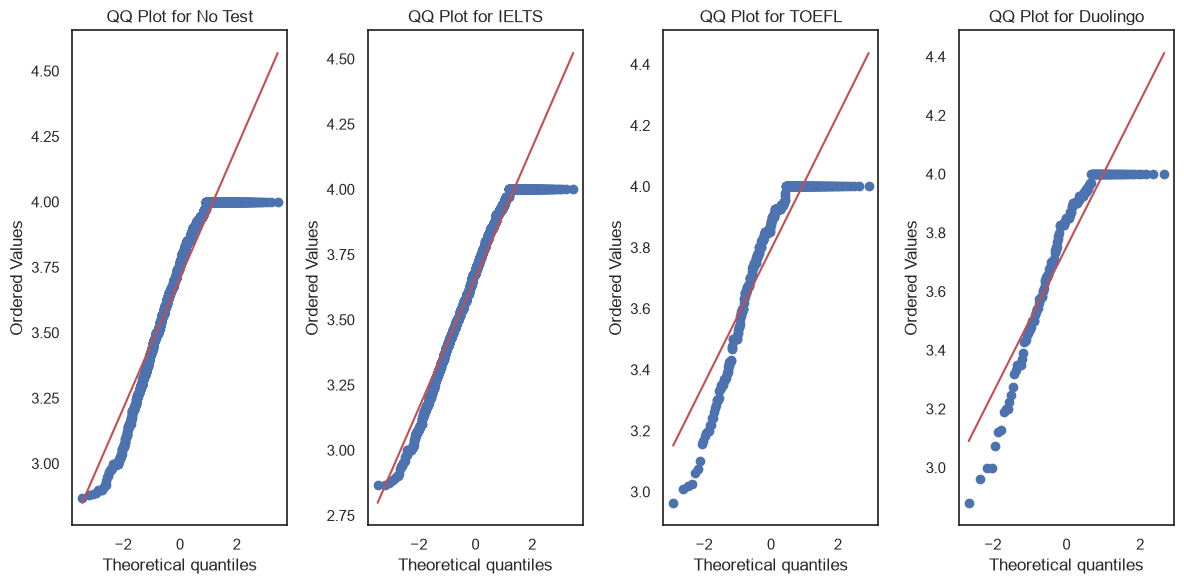

In [44]:
fig = get_qq_plot(df = df_cleaned, 
                  numeric_column='Cumulative_GPA',
                  categoric_column='TestName')
fig.show()

Q-Q plots indicate a strong divergence from the normal distribution, particularly evident in the right tail. This suggests that the assumption of normality may not hold for the data, which could impact the validity of parametric tests such as ANOVA. Further investigation and consideration of non-parametric alternatives are warranted.

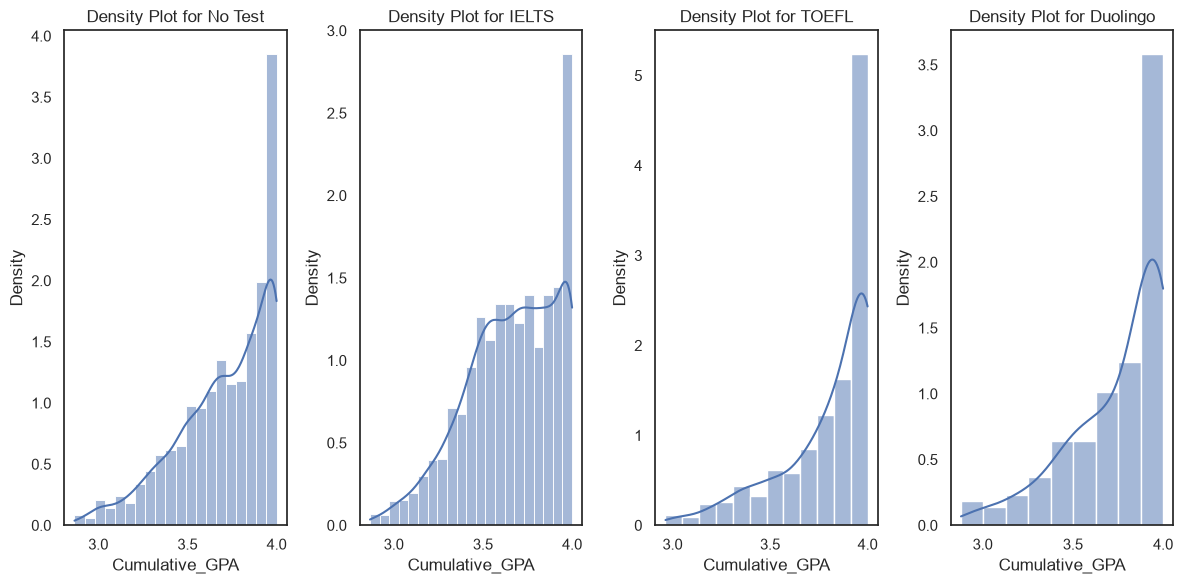

In [45]:
fig = get_density_plot(df=df_cleaned,
                       numeric_column='Cumulative_GPA',
                       categoric_column='TestName')

fig.show()

Histograms and density plots clearly illustrate that the datasets do not follow a normal distribution. This observation is consistent with the findings from the Q-Q plots and further underscores the non-normality of the data. As a result, parametric tests like ANOVA may not be appropriate, and alternative non-parametric tests should be considered for further analysis.

**Shapiro-Wilk Test of Normality**

The Shapiro-Wilk test was conducted to assess whether GPA within each group is consistent with a normal distribution.

**H<sub>0</sub>:** The sample data originates from a normally distributed population.

**H<sub>1</sub>:** The sample data does not originate from a normally distributed population.

This hypothesis test helps ascertain the suitability of parametric statistical methods, providing crucial insights into the distributional characteristics of the data.

In [46]:
result, normality_assumption = check_normality(df = df_cleaned, 
                                               numeric_column='Cumulative_GPA', 
                                               categoric_column='TestName', 
                                               alpha = 0.05)

if normality_assumption == False:
    print(f'Normality Assumption: Failed\n{result}')
else:
    print(f'Normality Assumption: Passed\n{result}')

Normality Assumption: Failed
- "No Test": p value = 0.00 - Not Normal
- "IELTS": p value = 0.00 - Not Normal
- "TOEFL": p value = 0.00 - Not Normal
- "Duolingo": p value = 0.00 - Not Normal



All categories failed the normality test, indicating a departure from the assumption of normality. To address this issue, the same dataset will be retested after undergoing transformation using the Box-Cox algorithm. This transformation aims to normalize the data distribution, potentially enabling the application of parametric statistical tests that rely on the assumption of normality.

In [47]:
df_cleaned = boxcox_tranformation(df=df_cleaned,
                                  numeric_column='Cumulative_GPA')

Now, the statistical tests should be reapplied to the transformed dataset to reassess the assumptions and conduct further analysis. This includes revisiting the normality test, as well as any other relevant tests, to evaluate the impact of the transformation on the distribution of the data and the validity of subsequent analyses.

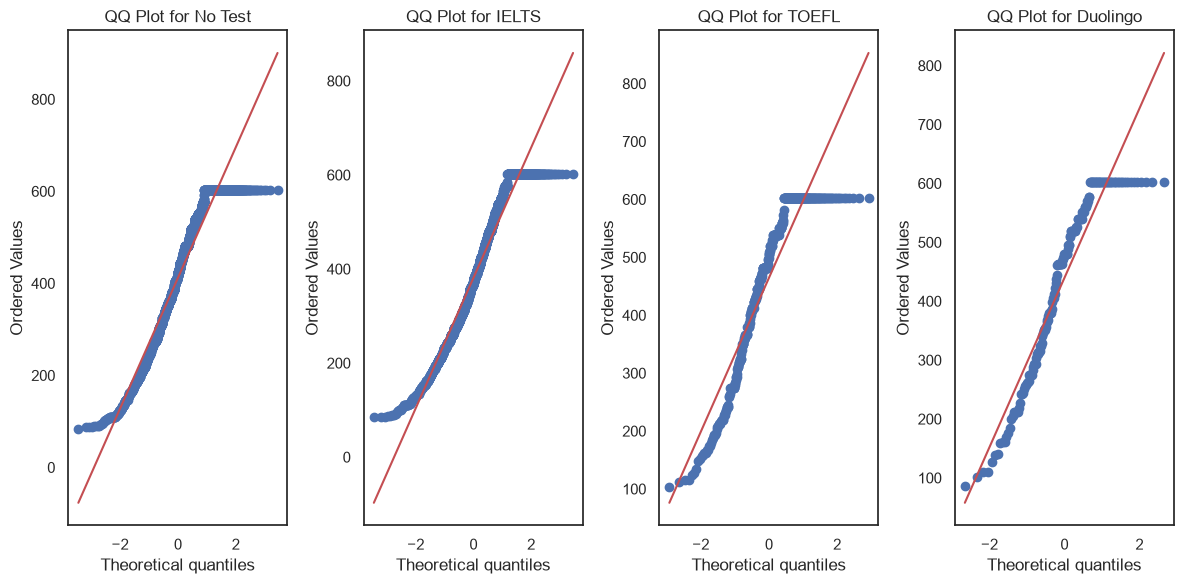

In [48]:
fig = get_qq_plot(df = df_cleaned, 
                  numeric_column='Cumulative_GPA_Transformed',
                  categoric_column='TestName')
fig.show()

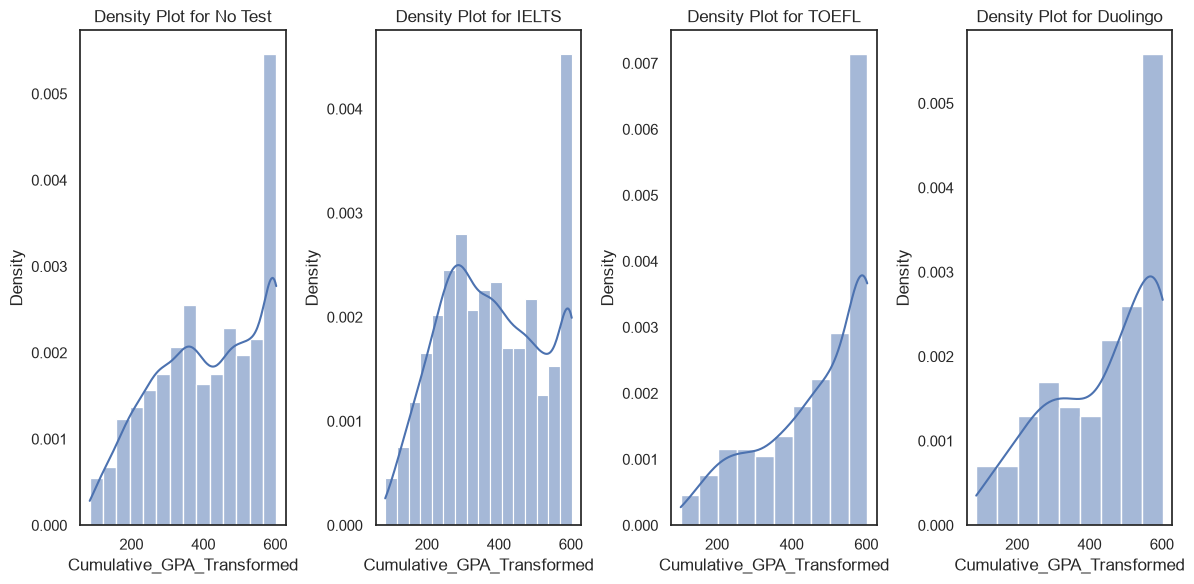

In [49]:
fig = get_density_plot(df=df_cleaned,
                       numeric_column='Cumulative_GPA_Transformed',
                       categoric_column='TestName')

fig.show()

In [50]:
result, normality_assumption = check_normality(df = df_cleaned, 
                                               numeric_column='Cumulative_GPA_Transformed', 
                                               categoric_column='TestName', 
                                               alpha = 0.05)

if normality_assumption == False:
    print(f'Normality Assumption: Failed\n{result}')
else:
    print(f'Normality Assumption: Passed\n{result}')

Normality Assumption: Failed
- "No Test": p value = 0.00 - Not Normal
- "IELTS": p value = 0.00 - Not Normal
- "TOEFL": p value = 0.00 - Not Normal
- "Duolingo": p value = 0.00 - Not Normal



The Box-Cox transformation did not resolve the normality issue: all four groups again failed the Shapiro-Wilk test (p-values displayed as 0.00 after rounding). This supports using non-parametric methods for the primary GPA comparison; the displayed p-values are rounded.

#### **3. Homogeneity of Variance (Homoscedasticity)**

**Bartlett's Test of Homoscedasticity**

Bartlett's Test will be utilized to assess the homoscedasticity assumption with the following hypotheses:

**H<sub>0</sub>:** Categories have equal variance (Homoscedastic).

**H<sub>1</sub>:** Categories do not have equal variance (Heteroscedastic).

This test assesses whether the Cumulative GPA variances are consistent across categories. The output is p=0.18, above alpha=0.05, so the test did not detect unequal variances; this is not proof that variances are equal. Bartlett's test is sensitive to non-normality, which was present here, so interpret this result cautiously.

In [51]:
result, normality_assumption = check_homoscedasticity(df = df_cleaned, 
                                                      numeric_column='Cumulative_GPA', 
                                                      categoric_column='TestName', 
                                                      alpha = 0.05)

print(result)

Homoscedasticity Assumption: Passed (p_value: 0.18)


### Statistical Test for Category Differences

#### ANOVA Test for Differences in Means

Although the dataset fails to meet the *Normality Assumption*, ANOVA test is applied to the dataset solely to gain an initial insight into the potential mean differences between the test categories.

The Analysis of Variance (ANOVA) test is a statistical method used to compare the means of three or more groups to determine if there are statistically significant differences between them. It assesses whether the variability between group means is greater than the variability within groups, by calculating the F-statistic, which is the ratio of the variance between groups to the variance within groups. ANOVA assumes that the data are normally distributed and have equal variances among groups. If the p-value associated with the F-statistic is below a pre-defined significance level (often denoted as alpha, typically 0.05), the null hypothesis of equal means across all groups is rejected, indicating that at least one group has a significantly different mean compared to the others. ANOVA does not identify which specific groups differ; additional post-hoc tests are typically conducted for pairwise comparisons between groups to determine where the differences lie.

**H<sub>0</sub>:** Categories have equal means.

**H<sub>1</sub>:** At least one category has differen mean.

In [52]:
result = anova_test(df=df_cleaned,
                    numeric_column='Cumulative_GPA',
                    categoric_column='TestName',
                    alpha=0.05)
print(result)

Reject the null hypothesis. At least one group has a different mean. (F: 39.99, p_value: 0.00)


The ANOVA output rejects equal means (F=39.99, p=0.00 as rounded in the output), indicating evidence that at least one group mean differs. Because the GPA groups failed the normality tests, treat this parametric result as exploratory rather than conclusive.

Pairwise mean comparisons after a significant ANOVA should control the family-wise Type I error rate. The following comparisons use a Bonferroni adjustment.

**Bonferroni Correction:** Bonferroni correction adjusts the significance level for each comparison by dividing the overall alpha by the number of comparisons. Here the adjusted alpha is 0.0083. The output reports different means for No Test vs. IELTS, No Test vs. TOEFL, IELTS vs. TOEFL, and IELTS vs. Duolingo; it does not report a difference for No Test vs. Duolingo or TOEFL vs. Duolingo. Since the normality assumption failed, interpret these parametric pairwise results cautiously.

In [53]:
result = t_test_bonferroni(df=df_cleaned,
                           numeric_column='Cumulative_GPA',
                           categoric_column='TestName',
                           alpha=0.05)
print(result)

- No Test vs. IELTS: Different means (p_value = 0.0000, adj_alpha = 0.0083)
- No Test vs. TOEFL: Different means (p_value = 0.0000, adj_alpha = 0.0083)
- No Test vs. Duolingo: Equal means (p_value = 0.0409, adj_alpha = 0.0083)
- IELTS vs. TOEFL: Different means (p_value = 0.0000, adj_alpha = 0.0083)
- IELTS vs. Duolingo: Different means (p_value = 0.0000, adj_alpha = 0.0083)
- TOEFL vs. Duolingo: Equal means (p_value = 0.0574, adj_alpha = 0.0083)



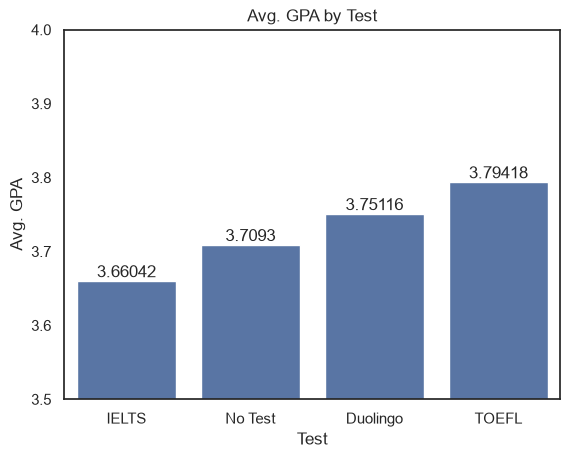

In [54]:
fig = bar_plot(df = summary_df_cleaned, 
               numeric_column = 'Avg. GPA',
               categoric_column='Test',
               y_lim=(3.5, 4),
               data_labels=True)

fig.show()

#### Non-Parametric Test for Differences in Medians

**Kruskal-Wallis Test**

When normality is violated, non-parametric tests such as Kruskal-Wallis provide an alternative to ANOVA. The Kruskal-Wallis test compares the rank distributions of independent groups. A significant result indicates that at least one group distribution differs; it can be interpreted as a difference in medians only when the group distributions have similar shapes. The output here rejects the null hypothesis (p=0.00 as rounded), indicating a difference among the four groups.

**H<sub>0</sub>:** The GPA distributions are the same across all categories.

**H<sub>1</sub>:** At least one category has a different GPA distribution.

In [55]:
result = kruskal_wallis_test(df=df_cleaned,
                             numeric_column='Cumulative_GPA',
                             categoric_column='TestName',
                             alpha=0.05)
print(result)

Reject the null hypothesis. At least one group has a different median. (p_value: 0.00)


**Mann-Whitney U Test**

The significant Kruskal-Wallis result indicates that at least one group distribution differs. Pairwise Mann-Whitney U tests compare the rank distributions of two independent groups; they do not establish median differences unless the groups have similarly shaped distributions. At alpha=0.05, the output reports differences for No Test vs. IELTS, No Test vs. TOEFL, No Test vs. Duolingo, IELTS vs. TOEFL, and IELTS vs. Duolingo. It reports no difference for TOEFL vs. Duolingo (displayed p=0.05). These six pairwise tests are unadjusted for multiple comparisons, so interpret them as exploratory.

**H<sub>0</sub>:** The two groups have the same GPA distribution.

**H<sub>1</sub>:** The two groups have different GPA distributions.

In [56]:
result = mann_whitney_test(df=df_cleaned,
                           numeric_column='Cumulative_GPA',
                           categoric_column='TestName',
                           alpha=0.05)
print(result)

- No Test vs. IELTS: Different medians (p_value = 0.00)
- No Test vs. TOEFL: Different medians (p_value = 0.00)
- No Test vs. Duolingo: Different medians (p_value = 0.01)
- IELTS vs. TOEFL: Different medians (p_value = 0.00)
- IELTS vs. Duolingo: Different medians (p_value = 0.00)
- TOEFL vs. Duolingo: Equal medians (p_value = 0.05)



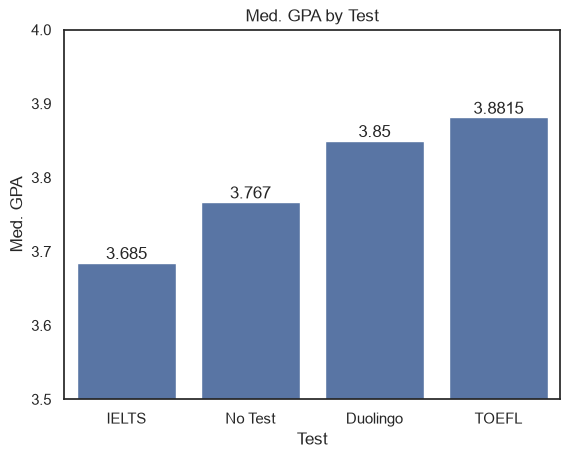

In [57]:
fig = bar_plot(df = summary_df_cleaned, 
               numeric_column = 'Med. GPA',
               categoric_column='Test',
               y_lim=(3.5, 4),
               data_labels=True)

fig.show()

#### Testing Withdrawal Proportions 

In [58]:
summary_df_cleaned.sort_values(by = 'Disc. %', ascending=False)

,Test,Count,Avg. GPA,Med. GPA,Disc.,Disc. %
1,No Test,2415,3.709296,3.7670,86,3.561077
2,TOEFL,398,3.794183,3.8815,9,2.261307
0,IELTS,2497,3.660416,3.6850,39,1.561874
3,Duolingo,175,3.751160,3.8500,2,1.142857


In [59]:
total_obs = sum(summary_df_cleaned['Count'])
total_disc = sum(summary_df_cleaned['Disc.'])
total_cont = total_obs - total_disc
discont_rate = total_disc / total_obs * 100

print(f'Total Number of Observations: {total_obs}')
print(f'Total Number of Discontinuation: {total_disc}')
print(f'Overall Discontinuation %: {discont_rate:#.2f}%')


Total Number of Observations: 5485
Total Number of Discontinuation: 136
Overall Discontinuation %: 2.48%


To test if Discontinuation Rate and ELP Test are related or not, there are two options: **Chi-Square Test of Independence** and **Fisher's Exact Test**

**Chi-Square Test of Independence**

It is a statistical test used to determine whether there is a significant association between two categorical variables. It's commonly used to analyze data in the form of a contingency table, where each cell represents the frequency of observations that fall into specific categories defined by the variables being studied. This test has following assumptions:

- *Independence of Observations:* The observations should be independent of each other. This means that the response of one individual should not influence the response of another individual.

- *Categorical Variables:* Both variables under investigation should be categorical. Each observation should fall into one of the defined categories for each variable.

- *Expected Cell Frequencies:* Each cell in the contingency table should ideally have an expected frequency of at least 5. When any expected cell frequency is less than 5, the reliability of the chi-square test decreases. However, the test can still be valid if the majority of expected cell frequencies are 5 or greater, and the overall sample size is large enough.

In the four-category table (5,485 records and 136 discontinuations), Duolingo has 2 observed discontinuations. Under independence, its expected discontinuation count is approximately 4.3 (136 x 175 / 5,485). Although Duolingo has an expected discontinuation count less than 5, the others have expected discontinuation counts higher than 5. Therefore, the test can still be valid as the majority of expected cell frequencies are 5 or greater, and the overall sample size is large enough.

| Test Name | Count | Disc. Count | Exp. Disc. Count | Disc. % |
| -------- | -------- | -------- | -------- | -------- |
| No Test | 2415 | 86 | 59.9 | 3.56 |
| TOEFL | 398 | 9 | 9.9 | 2.26 |
| IELTS | 2497 | 39 | 61.9 | 1.56 |
| Duolingo | 175 | 2 | 4.3 | 1.14 |


**Fisher's Exact Test**

It is a statistical test used to determine the significance of the association between two categorical variables. It's particularly suitable for small sample sizes or when the assumptions of the chi-square test are violated. Fisher's Exact Test provides exact probabilities for the observed distribution of frequencies in a contingency table. The assumptions are:

- **Categorical Variables:** Both variables being compared should be categorical. Each observation should fall into one of the defined categories for each variable.

- **Small Sample Sizes:** Fisher's Exact Test is particularly useful when the sample sizes are small. It provides exact probabilities without relying on asymptotic approximations, making it suitable for situations where the sample sizes are limited.

Pairwise Fisher exact tests were run with no multiple-comparison correction. For each pair, the hypotheses are:

**H<sub>0</sub>:** The discontinuation proportions are equal for the two categories.

**H<sub>1</sub>:** The discontinuation proportions differ for the two categories.

At alpha=0.05, the output identifies a difference only between IELTS and No Test (reported p=0.00, rounded); the other five pairwise comparisons are not significant. These pairwise results are unadjusted and are not an omnibus test of all categories.

In [60]:
result = fisher_exact_test(
    summary_df=summary_df_cleaned, 
    alpha=0.05, 
    p_val_correction = False
)  
print(result)

- IELTS vs. No Test: Different discontinuation rate (p_value = 0.00, alpha = 0.0500)
- IELTS vs. TOEFL: Equal discontinuation rate (p_value = 0.29, alpha = 0.0500)
- IELTS vs. Duolingo: Equal discontinuation rate (p_value = 1.00, alpha = 0.0500)
- No Test vs. TOEFL: Equal discontinuation rate (p_value = 0.23, alpha = 0.0500)
- No Test vs. Duolingo: Equal discontinuation rate (p_value = 0.12, alpha = 0.0500)
- TOEFL vs. Duolingo: Equal discontinuation rate (p_value = 0.52, alpha = 0.0500)



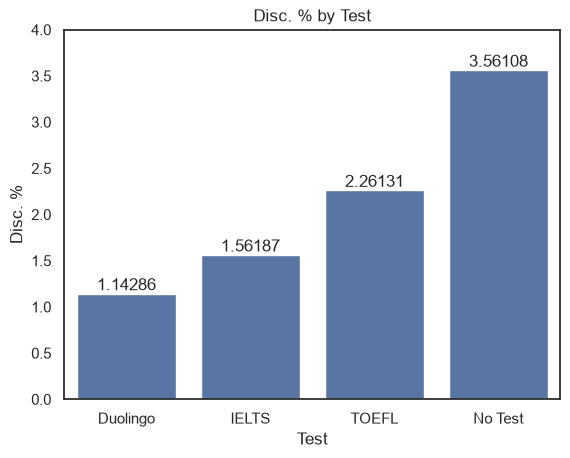

In [61]:
fig = bar_plot(df=summary_df_cleaned,
               numeric_column='Disc. %',
               categoric_column='Test',
               y_lim=(0, 4),
               data_labels=True)
fig.show()

In [62]:
summary_df_cleaned['Avg. GPA'] = summary_df_cleaned['Avg. GPA'].round(2)
summary_df_cleaned['Med. GPA'] = summary_df_cleaned['Med. GPA'].round(2)
summary_df_cleaned['Disc. %'] = summary_df_cleaned['Disc. %'].round(2)

summary_df_cleaned.sort_values(by = 'Disc. %', ascending = False)

,Count,Avg. GPA,Med. GPA,Disc.,Disc. %,Cont.
Test,,,,,,
No Test,2415,3.71,3.77,86,3.56,2329
TOEFL,398,3.79,3.88,9,2.26,389
IELTS,2497,3.66,3.68,39,1.56,2458
Duolingo,175,3.75,3.85,2,1.14,173


## Conclusion

In the records analyzed, TOEFL students had the highest average GPA (3.79), while the no-test group had the highest discontinuation rate (3.56%). Overall, 136 of 5,485 records were marked as discontinued (2.48%). The comparison found a difference in discontinuation rates between IELTS and the no-test group, but not between the other groups.

These findings point to questions worth exploring, especially why students with no test recorded have a higher observed discontinuation rate. They do not show that English tests cause higher grades or improve continuation. Differences in student backgrounds, program mix, or multiple records per student could also help explain the results, so these findings should inform further review rather than drive policy changes by themselves.